# 1. A first calculation, on the CPU and on the Apple GPU

A machine-learning interatomic potential (MLIP) predicts the energy of a set of atoms, and from it the
forces and the stress, at a small fraction of the cost of density-functional theory. Here we use
**7net-0**, a universal SevenNet model trained on the Materials Project, on a crystal of silicon.

We compute the same thing three ways:

1. on the **CPU**, with the reference e3nn code,
2. on the **Apple GPU**, still with the reference e3nn code,
3. on the **Apple GPU with the fused Metal kernels**, the default on `device='mps'`.

The physics must not change: we check that the three give the same energy, forces and stress, then
compare their speed. Without an Apple GPU the notebook runs the CPU part only.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

import _tutorial as T

warnings.filterwarnings('ignore', message='.*torch.jit.script.*')   # deprecation inside a dependency, harmless here
plt.rcParams['figure.dpi'] = 200   # sharp inline figures
T.machine_report()

machine : Apple M5 Pro, 52 GB memory, Darwin 27.2.0
python  : 3.13.9, torch 2.15.0, sevenn 0.12.2.dev0
Apple GPU (MPS): yes; fused kernels: available


## The structure

A 2 × 2 × 2 supercell of diamond silicon (64 atoms), with the atoms displaced slightly so that the forces
are not zero.

In [2]:
from ase.build import bulk

atoms = bulk('Si', 'diamond', a=5.43, cubic=True).repeat((2, 2, 2))
atoms.rattle(0.03, seed=1)
print(len(atoms), 'atoms, cell', atoms.cell.lengths())

64 atoms, cell [10.86 10.86 10.86]


## Energy, forces and stress with each backend

`T.calculator(model, device, mps_opt)` builds a `SevenNetCalculator`. In your own scripts this is simply
`SevenNetCalculator('7net-0', device='mps')`, which uses the fused kernels; `mps_opt='off'` keeps the
reference e3nn code.

In [3]:
results, calcs = {}, {}
for label, device, opt in T.available_backends():
    t = time.perf_counter()
    calc = T.calculator('7net-0', device, opt)
    a = atoms.copy()
    a.calc = calc
    results[label] = dict(E=a.get_potential_energy(), F=a.get_forces(), S=a.get_stress())
    setup = time.perf_counter() - t
    calcs[label] = (calc, device)
    print(f'{label:18s} E = {results[label]["E"]:.5f} eV   max |F| = {np.abs(results[label]["F"]).max():.4f} eV/Å'
          f'   (set-up and first call {setup:.1f} s)')

CPU, e3nn          E = -344.93195 eV   max |F| = 0.8693 eV/Å   (set-up and first call 4.1 s)


Apple GPU, e3nn    E = -344.93195 eV   max |F| = 0.8693 eV/Å   (set-up and first call 1.0 s)


Apple GPU, fused   E = -344.93195 eV   max |F| = 0.8693 eV/Å   (set-up and first call 0.9 s)


## Do they agree?

The three backends sum the same numbers in a different order, in single precision, so they differ in
the last digits only.

In [4]:
ref = results['CPU, e3nn']
for label, r in results.items():
    if label == 'CPU, e3nn':
        continue
    print(f'{label:18s} vs CPU:  |dE|/atom = {abs(r["E"] - ref["E"]) / len(atoms):.1e} eV,'
          f'  max |dF| = {np.abs(r["F"] - ref["F"]).max():.1e} eV/Å,'
          f'  max |dσ| = {np.abs(r["S"] - ref["S"]).max():.1e} eV/Å³')

Apple GPU, e3nn    vs CPU:  |dE|/atom = 0.0e+00 eV,  max |dF| = 2.0e-06 eV/Å,  max |dσ| = 5.9e-09 eV/Å³
Apple GPU, fused   vs CPU:  |dE|/atom = 0.0e+00 eV,  max |dF| = 2.1e-06 eV/Å,  max |dσ| = 7.3e-09 eV/Å³


Differences of order 10⁻⁶ eV/Å in the forces are float32 rounding. They are about a million times
smaller than the forces themselves, and far below the error of the model with respect to DFT.

## How fast is each?

The set-up time printed above includes loading the model and, for the fused kernels, generating and
compiling them; it is paid once. What matters for MD is the steady state: one call from new positions,
as in each MD step.

CPU, e3nn            148.5 ms per step


Apple GPU, e3nn       74.1 ms per step
Apple GPU, fused      14.8 ms per step


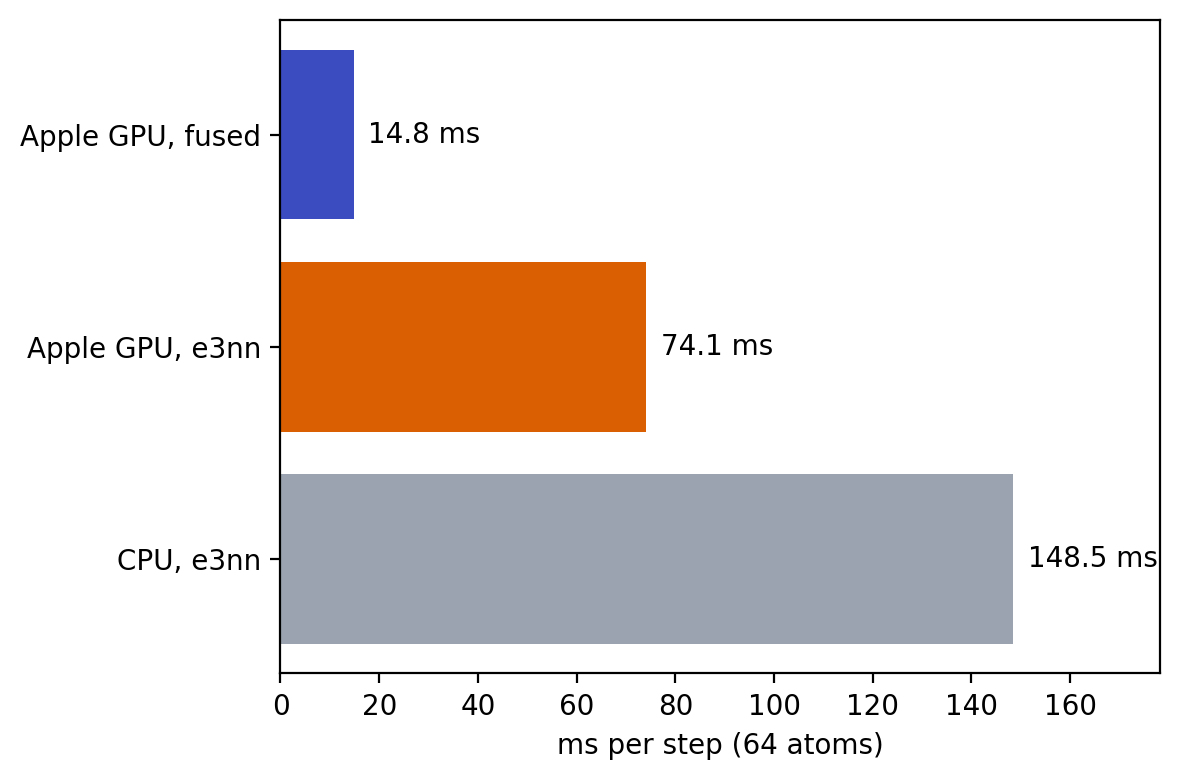

In [5]:
timing = {}
for label, (calc, device) in calcs.items():
    _, steady = T.time_calls(atoms, calc, device, n=10)
    timing[label] = steady
    print(f'{label:18s} {steady:7.1f} ms per step')

labels = list(timing)
fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(labels, [timing[k] for k in labels], color=['#9AA3AF', '#D95F02', '#3B4CC0'][:len(labels)])
ax.set_xlabel('ms per step (64 atoms)')
longest = max(timing.values())
for i, k in enumerate(labels):
    ax.text(timing[k] + 0.02 * longest, i, f'{timing[k]:.1f} ms', va='center')
ax.set_xlim(0, 1.2 * longest)
plt.tight_layout()
plt.show()

On an Apple GPU you should see:

* moving the reference code to the GPU helps little, or not at all, at this size: it runs many
  small operations, each writing a large temporary array, and is limited by memory traffic;
* the fused kernels compute each convolution in one pass without those arrays, and are an order of
  magnitude faster.

The answer is the same in all three cases. What changes is how large a system, and how long a
simulation, are practical: the next notebook runs molecular dynamics.

**Next experiment:** repeat the timing with a 3 × 3 × 3 supercell (216 atoms), or with the larger
model `'7net-l3i5'`.